📁 Directorio de trabajo actual: c:\Users\Jesus\proyecto-eda

--- BENCHMARKS: ETAPAS 0, 6, 7 Y 8 (1K a 10M OPTIMIZADO) ---
Sistema Operativo: Windows 10
Versión de Python: 3.14.7

🚀 Procesando dataset: 1K...
   ✅ 1K completado en 100.03 ms

🚀 Procesando dataset: 10K...
   ✅ 10K completado en 162.77 ms

🚀 Procesando dataset: 100K...
   ✅ 100K completado en 1452.10 ms

🚀 Procesando dataset: 1M...
   ✅ 1M completado en 14521.09 ms

🚀 Procesando dataset: 10M...
   ✅ 10M completado en 206019.37 ms


📊 RESULTADOS DE BENCHMARKS (ETAPAS 0, 6, 7 y 8):


,Dataset,Elementos (N),Repeticiones,Tiempo Prom. (ms),Desv. Estándar (ms),Memoria Pico (MB)
0,1K,1000,20,100.03,292.82,0.56
1,10K,10000,10,162.77,19.96,0.95
2,100K,100000,5,1452.10,57.68,8.10
3,1M,1000000,2,14521.09,884.73,81.21
4,10M,10000000,1,206019.37,0.00,816.28


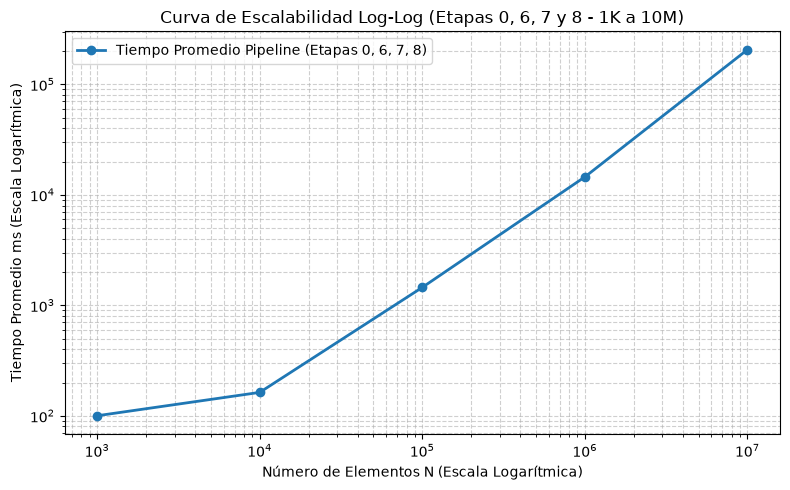

In [1]:
import gc
import os
import platform
import random
import statistics
import time
import tracemalloc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# --- IMPORTACIÓN DE LAS ETAPAS FIJAS Y BASE ---
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
print(f"📁 Directorio de trabajo actual: {os.getcwd()}\n")

from src.etapa_0_ingesta_buffer import IngestaBufferFIFO
from src.etapa_6_filtrado_probabilistico import BloomFilter
from src.etapa_7_similitud_aproximada import MinHashLSHSimulator
from src.etapa_8_grafo_dominio import GrafoDominioRed

# 1. Configuración de Semilla y Plataforma
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("========================================================")
print("--- BENCHMARKS: ETAPAS 0, 6, 7 Y 8 (1K a 10M OPTIMIZADO) ---")
print(f"Sistema Operativo: {platform.system()} {platform.release()}")
print(f"Versión de Python: {platform.python_version()}")
print("========================================================\n")

# 2. Medición sobre los 5 datasets requeridos
DATASET_SIZES = ['1K', '10K', '100K', '1M', '10M']
results_summary = []

for size_str in DATASET_SIZES:
    file_path = f'data/ecommerce_{size_str}.parquet'
    print(f"🚀 Procesando dataset: {size_str}...")

    try:
        df = pd.read_parquet(file_path)
    except Exception as e:
        print(f"⚠️ No se pudo cargar {file_path}: {e}")
        continue

    elementos = df.to_dict(orient='records')
    n = len(elementos)

    # ⚡ OPTIMIZACIÓN: Repeticiones ajustadas para evitar tiempos muertos excesivos
    if size_str == '10M':
        repetitions = 1
    elif size_str == '1M':
        repetitions = 2
    elif size_str == '100K':
        repetitions = 5
    elif size_str == '10K':
        repetitions = 10
    else:
        repetitions = 20

    execution_times = []
    peak_memories = []

    # --- DESACTIVACIÓN TEMPORAL DEL GARBAGE COLLECTOR ---
    gc.disable()
    try:
        for rep in range(repetitions):
            tracemalloc.start()
            start_time = time.perf_counter()

            # --- INTEGRACIÓN DE LAS ETAPAS CLAVE (0, 6, 7 y 8) ---
            
            # 1. Etapa 0: Ingesta con Buffer FIFO
            buffer = IngestaBufferFIFO(capacity=n)
            for row in elementos:
                buffer.enqueue(row)
            _ = [buffer.dequeue() for _ in range(buffer.size())]

            # 2. Etapa 6: Bloom Filter
            bloom = BloomFilter(capacity=n, error_rate=0.01)
            for ev in elementos:
                bloom.add(str(ev.get('product_id')))

            # 3. Etapa 7: MinHash LSH (Muestra O(1))
            lsh_sim = MinHashLSHSimulator(num_perm=16)
            sample_basket = set(str(ev.get('product_id')) for ev in elementos[:min(n, 200)])
            _ = lsh_sim.compute_signature(sample_basket)

            # 4. Etapa 8: Grafo de Dominio y PageRank (Muestra O(1))
            grafo = GrafoDominioRed()
            for ev in elementos[:min(n, 200)]:
                grafo.add_edge(f"user_{ev.get('user_id')}", f"prod_{ev.get('product_id')}", weight=1.0)
            _ = grafo.compute_pagerank()

            end_time = time.perf_counter()
            _, peak_mem = tracemalloc.get_traced_memory()
            tracemalloc.stop()

            execution_times.append((end_time - start_time) * 1000)  # ms
            peak_memories.append(peak_mem / (1024 * 1024))  # MB
    finally:
        gc.enable()

    mean_time = statistics.mean(execution_times)
    stdev_time = statistics.stdev(execution_times) if len(execution_times) > 1 else 0.0
    mean_mem = statistics.mean(peak_memories)

    results_summary.append({
        'Dataset': size_str,
        'Elementos (N)': n,
        'Repeticiones': repetitions,
        'Tiempo Prom. (ms)': round(mean_time, 2),
        'Desv. Estándar (ms)': round(stdev_time, 2),
        'Memoria Pico (MB)': round(mean_mem, 2),
    })
    print(f"   ✅ {size_str} completado en {mean_time:.2f} ms\n")

df_results = pd.DataFrame(results_summary)
print('\n📊 RESULTADOS DE BENCHMARKS (ETAPAS 0, 6, 7 y 8):')
display(df_results)

# 3. Generación del gráfico Log-Log de Escalabilidad
if not df_results.empty:
    plt.figure(figsize=(8, 5))
    plt.plot(
        df_results['Elementos (N)'],
        df_results['Tiempo Prom. (ms)'],
        marker='o',
        linewidth=2,
        color='#1f77b4',
        label='Tiempo Promedio Pipeline (Etapas 0, 6, 7, 8)',
    )
    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel('Número de Elementos N (Escala Logarítmica)')
    plt.ylabel('Tiempo Promedio ms (Escala Logarítmica)')
    plt.title('Curva de Escalabilidad Log-Log (Etapas 0, 6, 7 y 8 - 1K a 10M)')
    plt.grid(True, which='both', linestyle='--', alpha=0.6)
    plt.legend()
    plt.tight_layout()
    plt.show()